# CodeNova Internship — Sales Data Analysis

## 1. Project Overview

This project analyzes retail sales data to identify sales trends, profitability patterns, product performance, and regional opportunities.

## 2. Objectives

- Calculate total sales, total profit, profit margin, units sold, and Average Order Value (AOV).
- Analyze monthly and quarterly sales trends.
- Compare category and sub-category performance.
- Identify top-selling products and loss-making product categories.
- Evaluate regional sales distribution.
- Develop data-driven recommendations for business improvement.

## 3. Tools and Technologies

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Jupyter Notebook in Visual Studio Code

## 4. Dataset

The project uses the Sample Superstore retail dataset containing order details, customer segments, product categories, sales, discounts, quantities, and profits.

## 5. Key Performance Indicators

- **Total Sales:** $2,297,200.86
- **Total Profit:** $286,397.02
- **Units Sold:** 37,873
- **Overall Profit Margin:** 12.47%
- **Unique Orders:** 5,009
- **Average Order Value:** $458.61

SALES DATA ANALYSIS
Dataset shape: (9994, 22)

Column names:
['csvbase_row_id', '\ufeffRow ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

KEY BUSINESS METRICS
Total Sales: $2,297,200.86
Total Profit: $286,397.02
Total Units Sold: 37,873
Overall Profit Margin: 12.47%

MONTHLY SALES
Month
2014-01     14236.8950
2014-02      4519.8920
2014-03     55691.0090
2014-04     28295.3450
2014-05     23648.2870
2014-06     34595.1276
2014-07     33946.3930
2014-08     27909.4685
2014-09     81777.3508
2014-10     31453.3930
2014-11     78628.7167
2014-12     69545.6205
2015-01     18174.0756
2015-02     11951.4110
2015-03     38726.2520
2015-04     34195.2085
2015-05     30131.6865
2015-06     24797.2920
2015-07     28765.3250
2015-08     36898.3322
2015-09     64595.9180
2015-10     31404.923

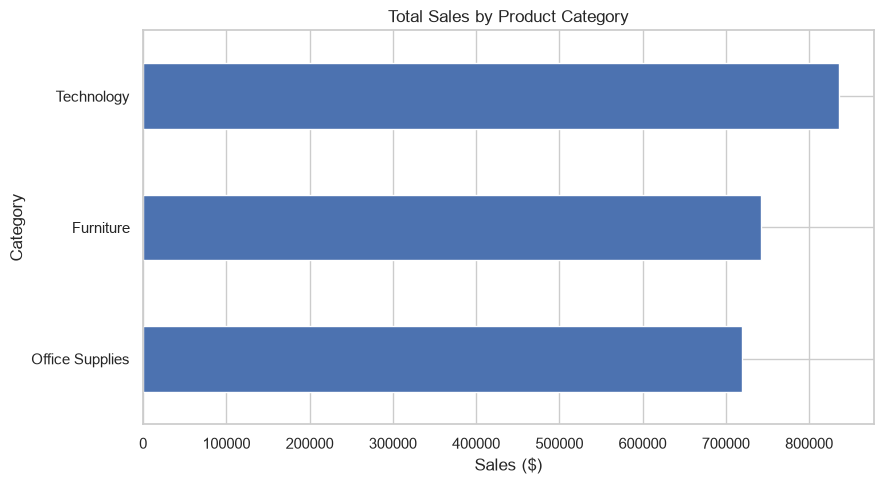

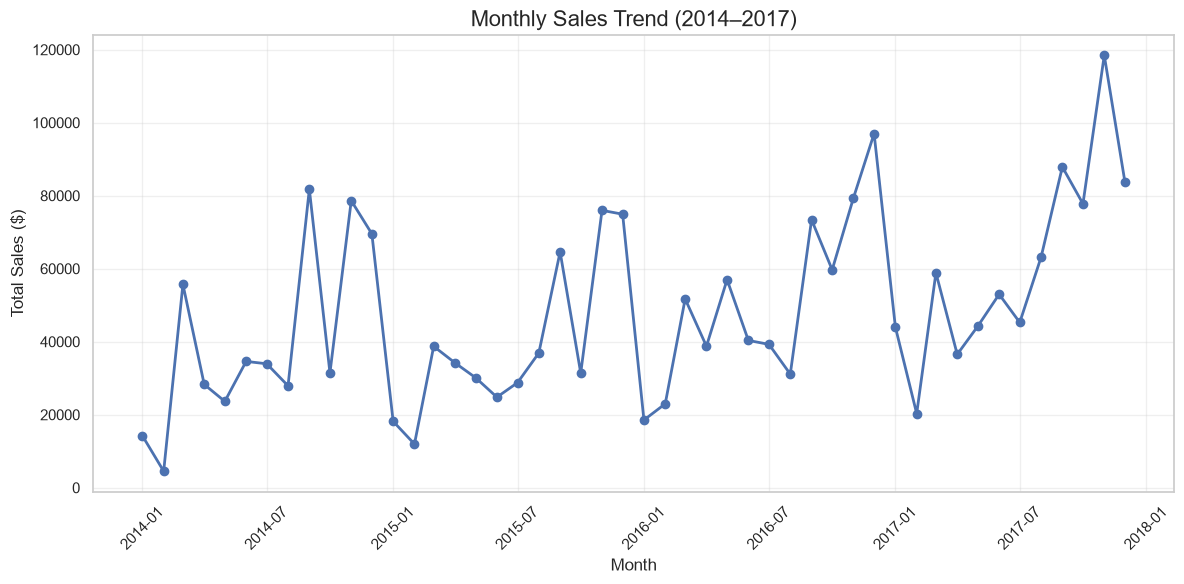

Chart saved as category_sales.png
Chart saved as monthly_sales_trend.png

QUARTERLY SALES ANALYSIS
Quarter
2014Q1     74447.7960
2014Q2     86538.7596
2014Q3    143633.2123
2014Q4    179627.7302
2015Q1     68851.7386
2015Q2     89124.1870
2015Q3    130259.5752
2015Q4    182297.0082
2016Q1     93237.1810
2016Q2    136082.3010
2016Q3    143787.3622
2016Q4    236098.7538
2017Q1    123144.8602
2017Q2    133764.3720
2017Q3    196251.9560
2017Q4    280054.0670
Freq: Q-DEC, Name: Sales, dtype: float64


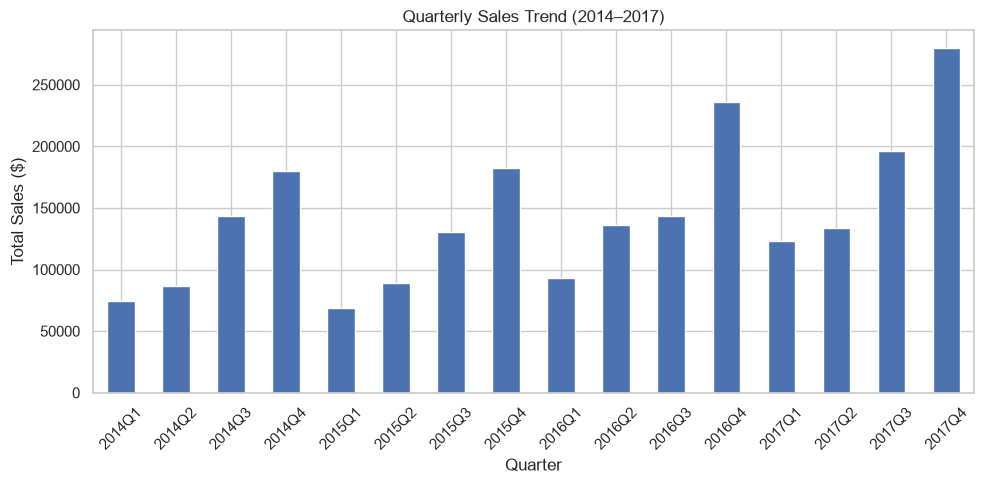

Chart saved as quarterly_sales.png

PROFIT ANALYSIS BY CATEGORY
Category
Furniture           18451.2728
Office Supplies    122490.8008
Technology         145454.9481
Name: Profit, dtype: float64


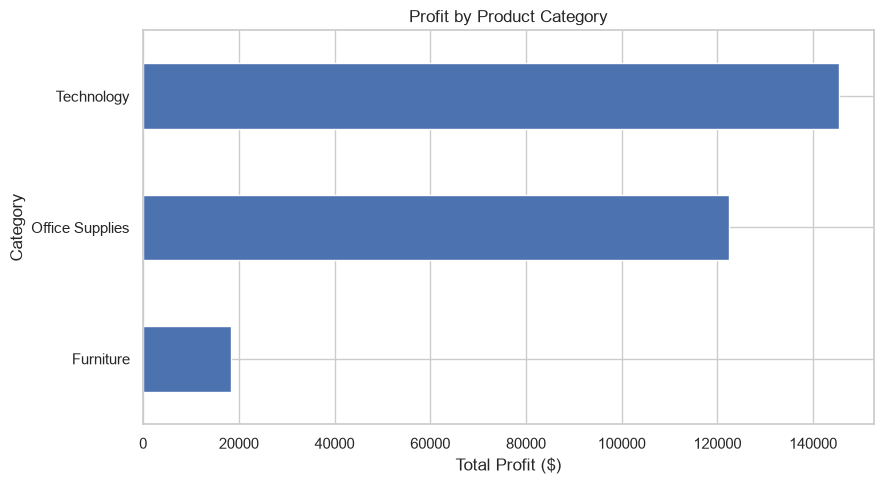

Chart saved as category_profit.png

REGION-WISE SALES
Region
South      391721.9050
Central    501239.8908
East       678781.2400
West       725457.8245
Name: Sales, dtype: float64


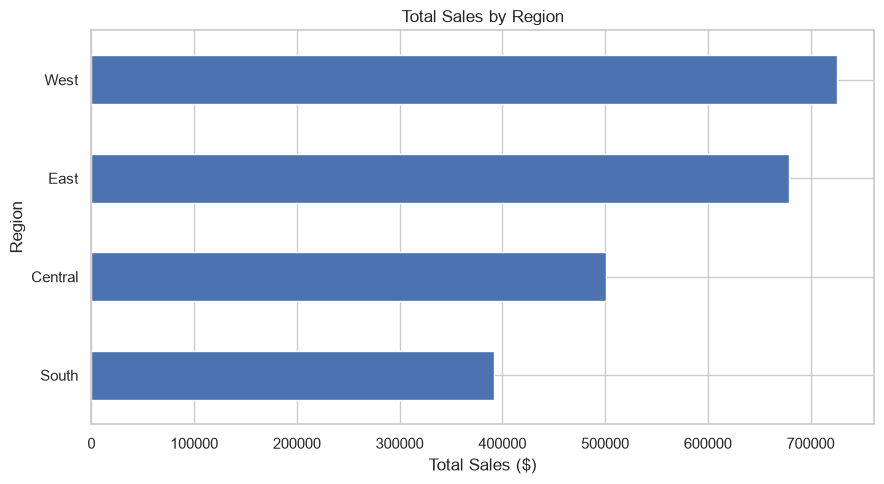

Chart saved as region_sales.png

SUB-CATEGORY PERFORMANCE
                    Sales      Profit  Quantity
Sub-Category                                   
Phones        330007.0540  44515.7306      3289
Chairs        328449.1030  26590.1663      2356
Storage       223843.6080  21278.8264      3158
Tables        206965.5320 -17725.4811      1241
Binders       203412.7330  30221.7633      5974
Machines      189238.6310   3384.7569       440
Accessories   167380.3180  41936.6357      2976
Copiers       149528.0300  55617.8249       234
Bookcases     114879.9963  -3472.5560       868
Appliances    107532.1610  18138.0054      1729
Furnishings    91705.1640  13059.1436      3563
Paper          78479.2060  34053.5693      5178
Supplies       46673.5380  -1189.0995       647
Art            27118.7920   6527.7870      3000
Envelopes      16476.4020   6964.1767       906
Labels         12486.3120   5546.2540      1400
Fasteners       3024.2800    949.5182       914


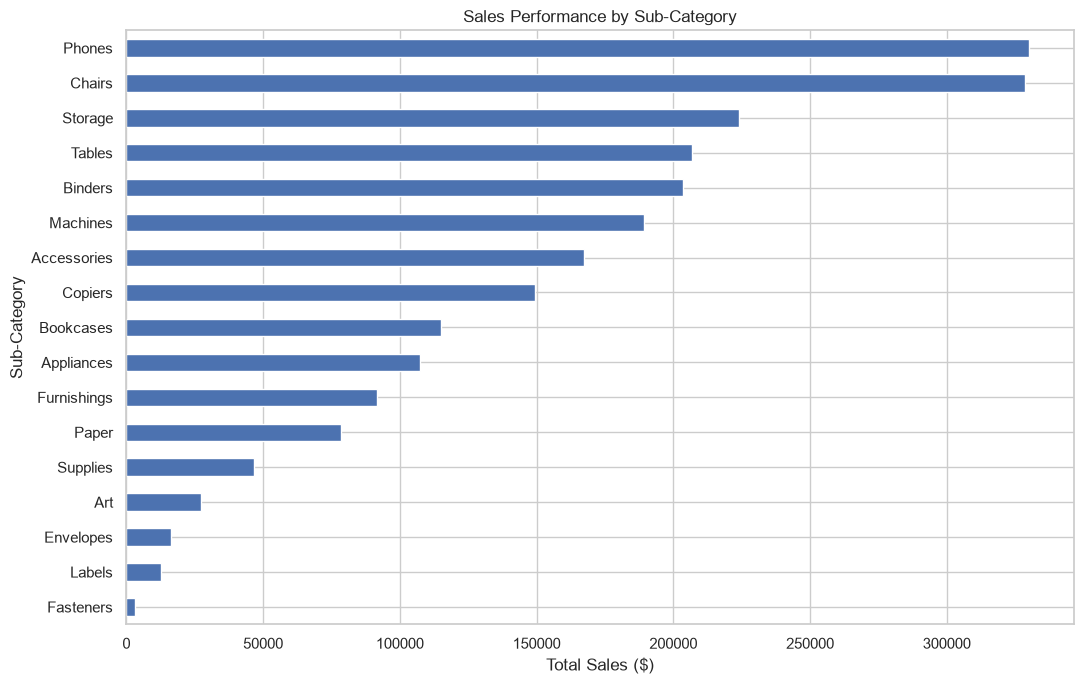

Chart saved as subcategory_sales.png

AVERAGE SALES BY MONTH
   Month_Name       Sales
0     January  249.146550
1    February  199.170838
2       March  294.548116
3       April  206.230731
4         May  210.923553
5        June  212.996763
6        July  207.377601
7      August  225.274877
8   September  222.451154
9     October  244.594609
10   November  239.606438
11   December  231.032318


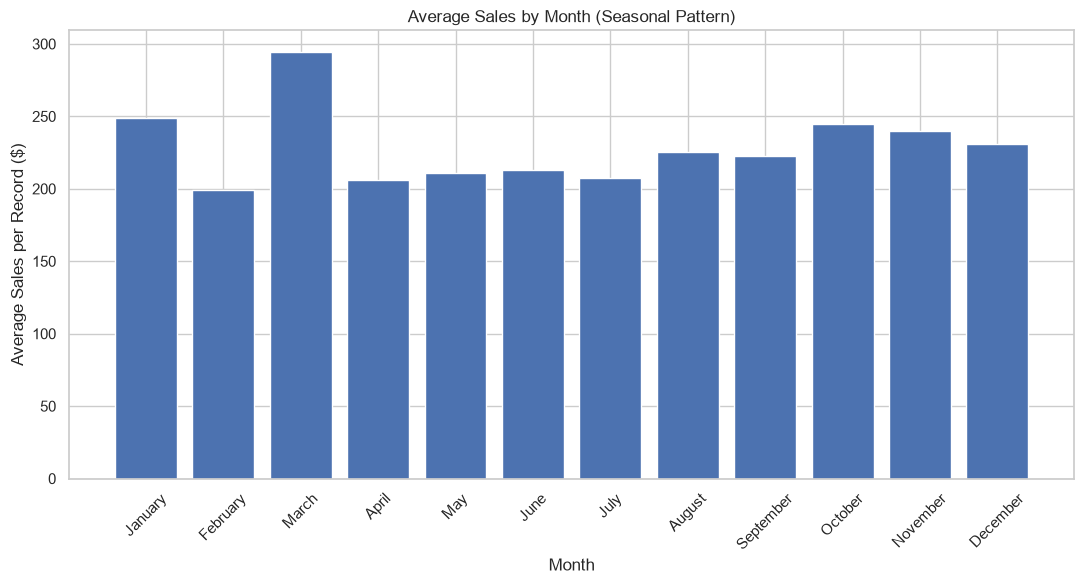

Chart saved as seasonal_sales.png

AVERAGE ORDER VALUE ANALYSIS
Total Unique Orders: 5009
Average Order Value: $458.61

TOP 10 PRODUCTS BY SALES
Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Open

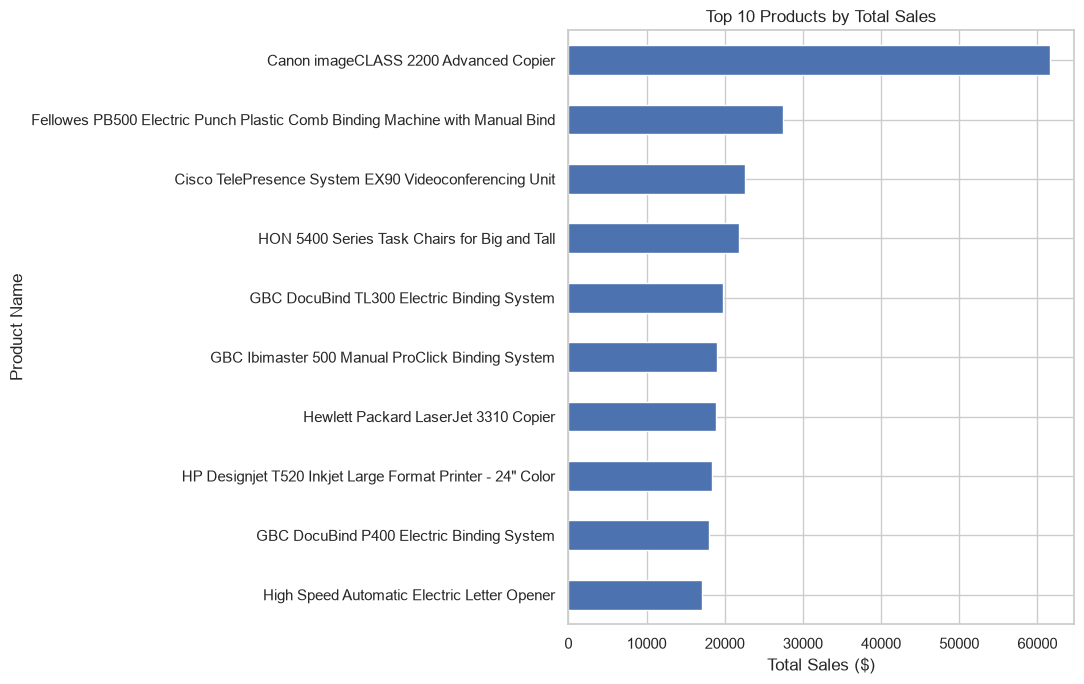

Chart saved as top_10_products.png


In [10]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Load dataset
file_path = Path("Sample-Superstore.csv")
df = pd.read_csv(file_path)

# Basic data inspection
print("SALES DATA ANALYSIS")
print("=" * 40)
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

# Convert date column
df["Order Date"] = pd.to_datetime(
    df["Order Date"], errors="coerce"
)

# Calculate key metrics
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_quantity = df["Quantity"].sum()
profit_margin = (total_profit / total_sales) * 100

print("\nKEY BUSINESS METRICS")
print("=" * 40)
print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Total Units Sold: {total_quantity:,}")
print(f"Overall Profit Margin: {profit_margin:.2f}%")

# Monthly sales trend
df["Month"] = df["Order Date"].dt.to_period("M")
monthly_sales = df.groupby("Month")["Sales"].sum()

print("\nMONTHLY SALES")
print(monthly_sales)

# Category performance
category_sales = df.groupby("Category")[
    ["Sales", "Profit", "Quantity"]
].sum()

print("\nCATEGORY PERFORMANCE")
print(category_sales)

# Save category chart
sns.set_theme(style="whitegrid")
category_sales["Sales"].sort_values().plot(
    kind="barh", figsize=(9, 5)
)
plt.title("Total Sales by Product Category")
plt.xlabel("Sales ($)")
plt.ylabel("Category")
plt.tight_layout()
plt.savefig("category_sales.png", dpi=300)
plt.show()


# Monthly Sales Trend Chart
monthly_sales.index = monthly_sales.index.to_timestamp()

plt.figure(figsize=(12, 6))
plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Sales Trend (2014–2017)", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("monthly_sales_trend.png", dpi=300)
plt.show()

print("Chart saved as category_sales.png")
print("Chart saved as monthly_sales_trend.png")


# Quarterly Sales Analysis
df["Quarter"] = df["Order Date"].dt.to_period("Q")

quarterly_sales = df.groupby("Quarter")["Sales"].sum()

print("\nQUARTERLY SALES ANALYSIS")
print(quarterly_sales)

plt.figure(figsize=(10, 5))
quarterly_sales.plot(kind="bar")

plt.title("Quarterly Sales Trend (2014–2017)")
plt.xlabel("Quarter")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("quarterly_sales.png", dpi=300)
plt.show()

print("Chart saved as quarterly_sales.png")


# Profit Analysis by Category
category_profit = df.groupby("Category")["Profit"].sum()

print("\nPROFIT ANALYSIS BY CATEGORY")
print(category_profit)

plt.figure(figsize=(9, 5))
category_profit.sort_values().plot(kind="barh")

plt.title("Profit by Product Category")
plt.xlabel("Total Profit ($)")
plt.ylabel("Category")
plt.tight_layout()

plt.savefig("category_profit.png", dpi=300)
plt.show()

print("Chart saved as category_profit.png")


# Geographic Sales Analysis
region_sales = df.groupby("Region")["Sales"].sum().sort_values()

print("\nREGION-WISE SALES")
print(region_sales)

plt.figure(figsize=(9, 5))
region_sales.plot(kind="barh")

plt.title("Total Sales by Region")
plt.xlabel("Total Sales ($)")
plt.ylabel("Region")
plt.tight_layout()

plt.savefig("region_sales.png", dpi=300)
plt.show()

print("Chart saved as region_sales.png")


# Sub-Category Performance Analysis
subcategory_performance = df.groupby("Sub-Category")[
    ["Sales", "Profit", "Quantity"]
].sum().sort_values("Sales", ascending=False)

print("\nSUB-CATEGORY PERFORMANCE")
print(subcategory_performance)

plt.figure(figsize=(11, 7))
subcategory_performance["Sales"].sort_values().plot(
    kind="barh"
)

plt.title("Sales Performance by Sub-Category")
plt.xlabel("Total Sales ($)")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.savefig("subcategory_sales.png", dpi=300)
plt.show()

print("Chart saved as subcategory_sales.png")


# Seasonal Sales Analysis
df["Month_Name"] = df["Order Date"].dt.month_name()
df["Month_Number"] = df["Order Date"].dt.month

seasonal_sales = df.groupby(
    ["Month_Number", "Month_Name"]
)["Sales"].mean().reset_index()

seasonal_sales = seasonal_sales.sort_values("Month_Number")

print("\nAVERAGE SALES BY MONTH")
print(seasonal_sales[["Month_Name", "Sales"]])

plt.figure(figsize=(11, 6))
plt.bar(
    seasonal_sales["Month_Name"],
    seasonal_sales["Sales"]
)

plt.title("Average Sales by Month (Seasonal Pattern)")
plt.xlabel("Month")
plt.ylabel("Average Sales per Record ($)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("seasonal_sales.png", dpi=300)
plt.show()

print("Chart saved as seasonal_sales.png")


# Average Order Value (AOV)
total_orders = df["Order ID"].nunique()
aov = df["Sales"].sum() / total_orders

print("\nAVERAGE ORDER VALUE ANALYSIS")
print("Total Unique Orders:", total_orders)
print(f"Average Order Value: ${aov:,.2f}")

# Top 10 Products by Sales
top_products = (
    df.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\nTOP 10 PRODUCTS BY SALES")
print(top_products)

plt.figure(figsize=(11, 7))
top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Total Sales")
plt.xlabel("Total Sales ($)")
plt.ylabel("Product Name")
plt.tight_layout()
plt.savefig("top_10_products.png", dpi=300)
plt.show()

print("Chart saved as top_10_products.png")


In [11]:
# DATA VALIDATION

print("DATA VALIDATION REPORT")
print("-" * 40)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum().sum())

# Check duplicate rows
print("\nDuplicate rows:")
print(df.duplicated().sum())

# Verify total sales and profit
print("\nTotal Sales:", round(df["Sales"].sum(), 2))
print("Total Profit:", round(df["Profit"].sum(), 2))

# Reconcile sales by category
category_total = df.groupby("Category")["Sales"].sum().sum()

print("\nCategory Sales Reconciliation:")
print("Overall Sales:", round(df["Sales"].sum(), 2))
print("Category Sales Total:", round(category_total, 2))
print("Totals Match:", round(df["Sales"].sum(), 2) == round(category_total, 2))

# Reconcile sales by region
region_total = df.groupby("Region")["Sales"].sum().sum()

print("\nRegion Sales Reconciliation:")
print("Overall Sales:", round(df["Sales"].sum(), 2))
print("Region Sales Total:", round(region_total, 2))
print("Totals Match:", round(df["Sales"].sum(), 2) == round(region_total, 2))

DATA VALIDATION REPORT
----------------------------------------

Missing values:
0

Duplicate rows:
0

Total Sales: 2297200.86
Total Profit: 286397.02

Category Sales Reconciliation:
Overall Sales: 2297200.86
Category Sales Total: 2297200.86
Totals Match: True

Region Sales Reconciliation:
Overall Sales: 2297200.86
Region Sales Total: 2297200.86
Totals Match: True


In [12]:
# PROFIT MARGIN ANALYSIS

category_margin = df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
)

category_margin["Profit_Margin_%"] = (
    category_margin["Total_Profit"]
    / category_margin["Total_Sales"]
) * 100

print("PROFIT MARGIN BY CATEGORY")
print(category_margin.round(2))

print("\nPROFIT MARGIN BY SUB-CATEGORY")

subcategory_margin = df.groupby("Sub-Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
)

subcategory_margin["Profit_Margin_%"] = (
    subcategory_margin["Total_Profit"]
    / subcategory_margin["Total_Sales"]
) * 100

print(
    subcategory_margin
    .sort_values("Profit_Margin_%", ascending=False)
    .round(2)
)

PROFIT MARGIN BY CATEGORY
                 Total_Sales  Total_Profit  Profit_Margin_%
Category                                                   
Furniture          741999.80      18451.27             2.49
Office Supplies    719047.03     122490.80            17.04
Technology         836154.03     145454.95            17.40

PROFIT MARGIN BY SUB-CATEGORY
              Total_Sales  Total_Profit  Profit_Margin_%
Sub-Category                                            
Labels           12486.31       5546.25            44.42
Paper            78479.21      34053.57            43.39
Envelopes        16476.40       6964.18            42.27
Copiers         149528.03      55617.82            37.20
Fasteners         3024.28        949.52            31.40
Accessories     167380.32      41936.64            25.05
Art              27118.79       6527.79            24.07
Appliances      107532.16      18138.01            16.87
Binders         203412.73      30221.76            14.86
Furnishings     

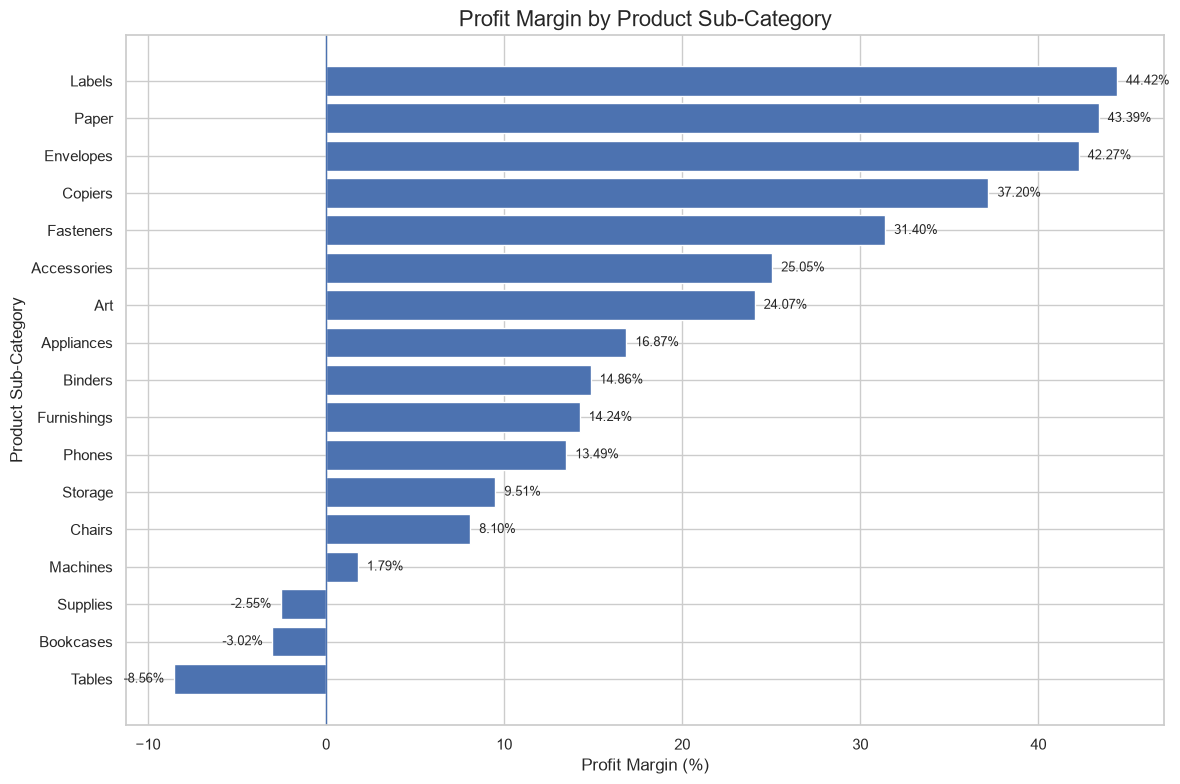

Chart saved as subcategory_profit_margin.png


In [13]:
# SUB-CATEGORY PROFIT MARGIN CHART

import matplotlib.pyplot as plt

margin_data = subcategory_margin.sort_values("Profit_Margin_%")

plt.figure(figsize=(12, 8))

bars = plt.barh(
    margin_data.index,
    margin_data["Profit_Margin_%"]
)

plt.axvline(0, linewidth=1)
plt.title("Profit Margin by Product Sub-Category", fontsize=16)
plt.xlabel("Profit Margin (%)")
plt.ylabel("Product Sub-Category")

for bar in bars:
    width = bar.get_width()
    offset = 0.5 if width >= 0 else -0.5
    alignment = "left" if width >= 0 else "right"

    plt.text(
        width + offset,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}%",
        va="center",
        ha=alignment,
        fontsize=9
    )

plt.tight_layout()
plt.savefig("subcategory_profit_margin.png", dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved as subcategory_profit_margin.png")

CUSTOMER SEGMENT PERFORMANCE
             Total_Sales  Total_Profit  Orders  Profit_Margin_%
Segment                                                        
Consumer      1161401.34     134119.21    2586            11.55
Corporate      706146.37      91979.13    1514            13.03
Home Office    429653.15      60298.68     909            14.03


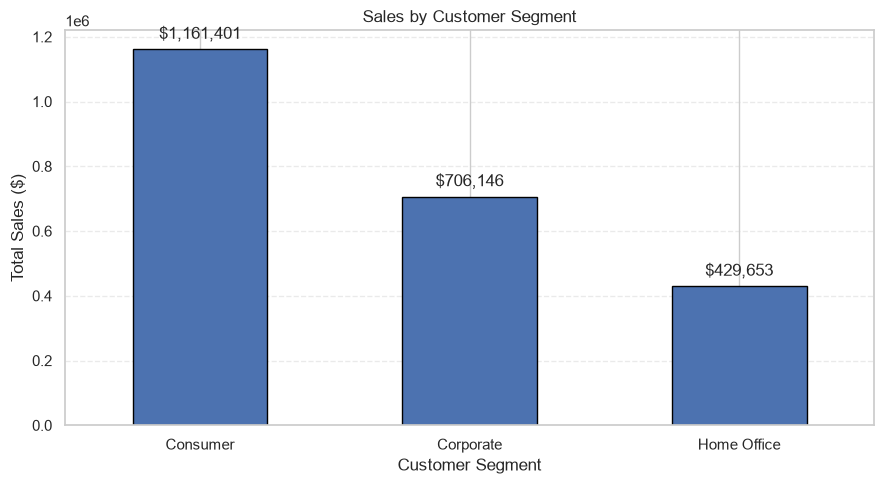

In [14]:
# CUSTOMER SEGMENT ANALYSIS

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load dataset if df is not already available
if "df" not in globals():
    file_path = Path("Sample-Superstore.csv")
    if not file_path.exists():
        file_path = Path("superstore_sales.csv")
    df = pd.read_csv(file_path, encoding="utf-8-sig")

# Calculate segment performance
segment_sales = df.groupby("Segment").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique")
)

segment_sales["Profit_Margin_%"] = (
    segment_sales["Total_Profit"] / segment_sales["Total_Sales"]
) * 100

print("CUSTOMER SEGMENT PERFORMANCE")
print(segment_sales.round(2))

# Plot sales with values
ax = segment_sales["Total_Sales"].plot(
    kind="bar",
    figsize=(9, 5),
    title="Sales by Customer Segment",
    edgecolor="black"
)

plt.xlabel("Customer Segment")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"${height:,.0f}",
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig("segment_sales.png", dpi=300, bbox_inches="tight")
plt.show()